# Reproduce Fig.2 Part 1 - GEM 2nd & 3rd passes
To keep thing simple, here we will continue from GEM 1st pass (see `fig2_1st_pass.ipynb`) by using its saved 
`data/first_pass_fit_results.pkl` and `data/posthoc_first_pass_dict.pkl`, we will do 2nd-pass and 3rd-pass manually here to reproduce figure 2 and Table 4 in the paper

Firstly, we set up all configurations

In [1]:
## CONFIG
GH_NODES = 200
MAX_ITER = 200
MU_GAMMA = 0.1
MU_KAPPA = -0.01
KAPPA_MAX=-0.00001

OPTIMAL_KAPPA_INIT = True 

RIDGE_KAPPA = 0.1
RIDGE_GAMMA = 0.1
RIDGE_B = 0.1
RIDGE_A = 0.5
RIDGE_X0 = 1000

strict_Y_int = False

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib

# Graphical configs
# 1. Reset seaborn to baseline
sns.set_style('whitegrid')
sns.set_context('paper') # Remove font_scale!

# 2. Hardcode the absolute font sizes for publication
plt.rcParams.update({
    'font.size': 9,             # Global baseline
    'figure.titlesize': 9,      # Global figure titles (Added)
    'axes.titlesize': 10,       # Title of the subplot (ax.set_title)
    'axes.labelsize': 9,        # X and Y axis labels
    'xtick.labelsize': 8,       # Numbers on the X axis
    'ytick.labelsize': 8,       # Numbers on the Y axis
    'legend.fontsize': 8,       # Legend text
    'legend.title_fontsize': 8  # Legend title
})

### Data loading

In [3]:
B_coding = pd.read_csv('data/B_coding.csv', index_col=0)
B_language = pd.read_csv('data/B_language.csv', index_col=0)
B_reasoning = pd.read_csv('data/B_reasoning.csv', index_col=0)
B_math = pd.read_csv('data/B_math.csv', index_col=0)

Y_coding = pd.read_csv('data/Y_coding.csv', index_col=0)
Y_language = pd.read_csv('data/Y_language.csv', index_col=0)
Y_reasoning = pd.read_csv('data/Y_reasoning.csv', index_col=0)
Y_math = pd.read_csv('data/Y_math.csv', index_col=0)

c_coding = pd.read_csv('data/c_coding.csv', index_col=0).set_index('question_id')
c_language = pd.read_csv('data/c_language.csv', index_col=0).set_index('question_id')
c_reasoning = pd.read_csv('data/c_reasoning.csv', index_col=0).set_index('question_id')
c_math = pd.read_csv('data/c_math.csv', index_col=0).set_index('question_id')

In [4]:
B = pd.concat([B_language, B_coding, B_reasoning, B_math],axis=0)
Y = pd.concat([Y_language, Y_coding, Y_reasoning, Y_math],axis=0)
c = pd.concat([c_language, c_coding, c_reasoning, c_math],axis=0)

In [5]:
from reasoning_aware_irt.livebench_utils import reindex
_ = reindex(Y, B, c) # little helper to make sure that all dataframes have exactly the same sorted question_id indices

the model_id Y/B sequence is great!!
the question_id Y/B sequence is great!!
the question_id Y/c sequence is great!!


In [6]:
Y_ij = Y.values
B_ij = B.values.astype(int)
c_i = c.values.squeeze()

print(Y_ij.shape, B_ij.shape)
print(Y_ij.mean(), B_ij.mean())
print(c_i.shape, c_i[:5])

(786, 42) (786, 42)
0.39359059581389527 1310.9940930570701
(786,) [1.e-05 1.e-05 1.e-02 1.e-02 1.e-02]


In [7]:
model_list = np.array(list(B.columns)) 
print(model_list.shape, model_list[-5:])

(42,) ['baidu/ernie-4.5-21b-a3b-thinking' 'allenai/olmo-3-7b-think'
 'qwen/qwen3-30b-a3b-thinking-2507' 'google/gemma-3-27b-it:free'
 'meta-llama/llama-4-scout']


In [8]:
x0_j = np.log1p(B_ij.mean(axis=0)) # budget regularizer (Eq.12 in the paper)

# Evaluate with Reasoning-Aware 3PL's GEM

In [9]:
from reasoning_aware_irt.gem_quad import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem_quad import ReasoningAware3PLQuadraticCalibrator as ReasoningAware3PLCalibrator

### 2nd-pass
We continue from the results of `fig2_1st_pass.ipynb`

In [10]:
fit_results = joblib.load('data/first_pass_fit_results.pkl')
first_pass_dict = joblib.load('data/posthoc_first_pass_dict.pkl')

x0_j = np.log1p(first_pass_dict['best_B_j_list'])

init_param_dict = {}
init_param_dict['a_i'] = fit_results.a_i
init_param_dict['b_i'] = fit_results.b_i
init_param_dict['gamma_j'] = np.array(first_pass_dict['gamma_list'])
init_param_dict['kappa_j'] = np.array(first_pass_dict['kappa_list'])

In [11]:
data = CalibrationData(Y_ij=Y_ij, B_ij=B_ij, c_i=c_i)

In [ ]:
%%time

cfg = CalibrationConfig(
gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
ridge_kappa=RIDGE_KAPPA, ridge_gamma=RIDGE_GAMMA, 
ridge_a=RIDGE_A, mu_gamma=MU_GAMMA, ridge_b=RIDGE_B,
mu_kappa=MU_KAPPA, kappa_max=KAPPA_MAX, tol=0.001,
ridge_x0=RIDGE_X0, x0_j=x0_j, optimal_kappa=OPTIMAL_KAPPA_INIT)

calibrator = ReasoningAware3PLCalibrator(cfg)
print(cfg)

fit_results = calibrator.fit(data, strict_Y_int=strict_Y_int, init_param_dict=init_param_dict)

CalibrationConfig(gh_nodes=200, max_iter=200, tol=0.001, seed=0, verbose=True, use_quadratic=True, use_pin_posthoc=False, optimal_kappa=True, tau=0.75, ridge_a=0.5, ridge_b=0.1, ridge_gamma=0.1, ridge_kappa=0.1, mu_a=1.0, mu_b=0.0, mu_gamma=0.1, mu_kappa=-0.01, a_min=0.05, a_max=5.0, gamma_min=0.0, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-05, x0_j=array([5.18738581, 6.80128303, 6.20253552, 6.10255859, 5.43807931,
       6.60529792, 6.05678401, 3.13549422, 5.99893656, 5.53733427,
       4.31748811, 5.24702407, 5.420535  , 5.97888576, 3.66356165,
       4.78749174, 5.05624581, 6.74405919, 4.96284463, 6.52795792,
       3.8501476 , 6.3044488 , 5.14166356, 5.54126355, 3.4657359 ,
       5.60211882, 7.75362355, 4.44265126, 5.83188248, 6.19440539,
       4.47733681, 3.98898405, 3.80666249, 4.59511985, 7.97418867,
       8.31678913, 9.02653772, 8.60995467, 8.94141463, 9.13205445,
       6.32972091, 6.67582322]), ridge_x0=1000)
iter   1  ll=-13807.296618   dLL=nan
iter   2  ll=-13787.66562

In [13]:
fit_results.info['c_i'] = c_i
fit_results.info['B_ij'] = B_ij

### post-hoc refinement of the 2nd-pass

In [14]:
from reasoning_aware_irt.posthoc import plot_sliced_bins

/workspaces/reasoning-aware-irt/reasoning_aware_irt/posthoc.py:222: SyntaxWarning: invalid escape sequence '\i'
  title = f"{slice_label} $\in$ [{slice_edges[target_slice_idx]:.2f}, {slice_edges[target_slice_idx+1]:.2f}]"


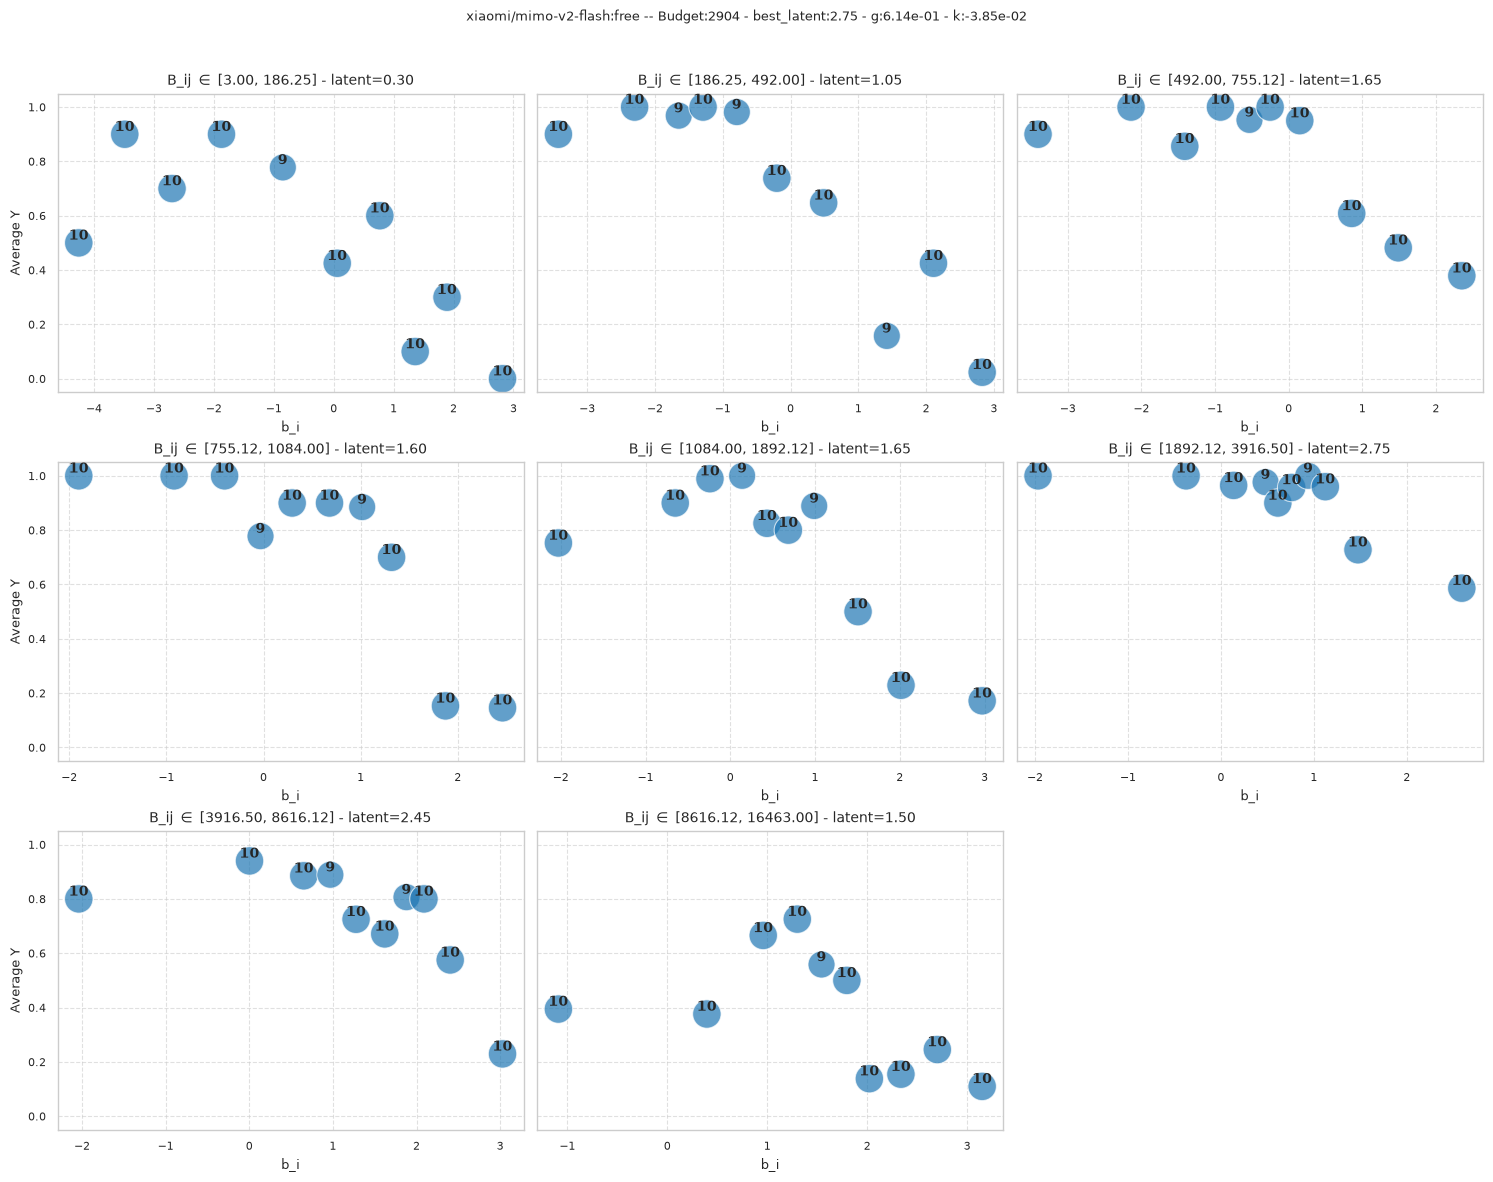

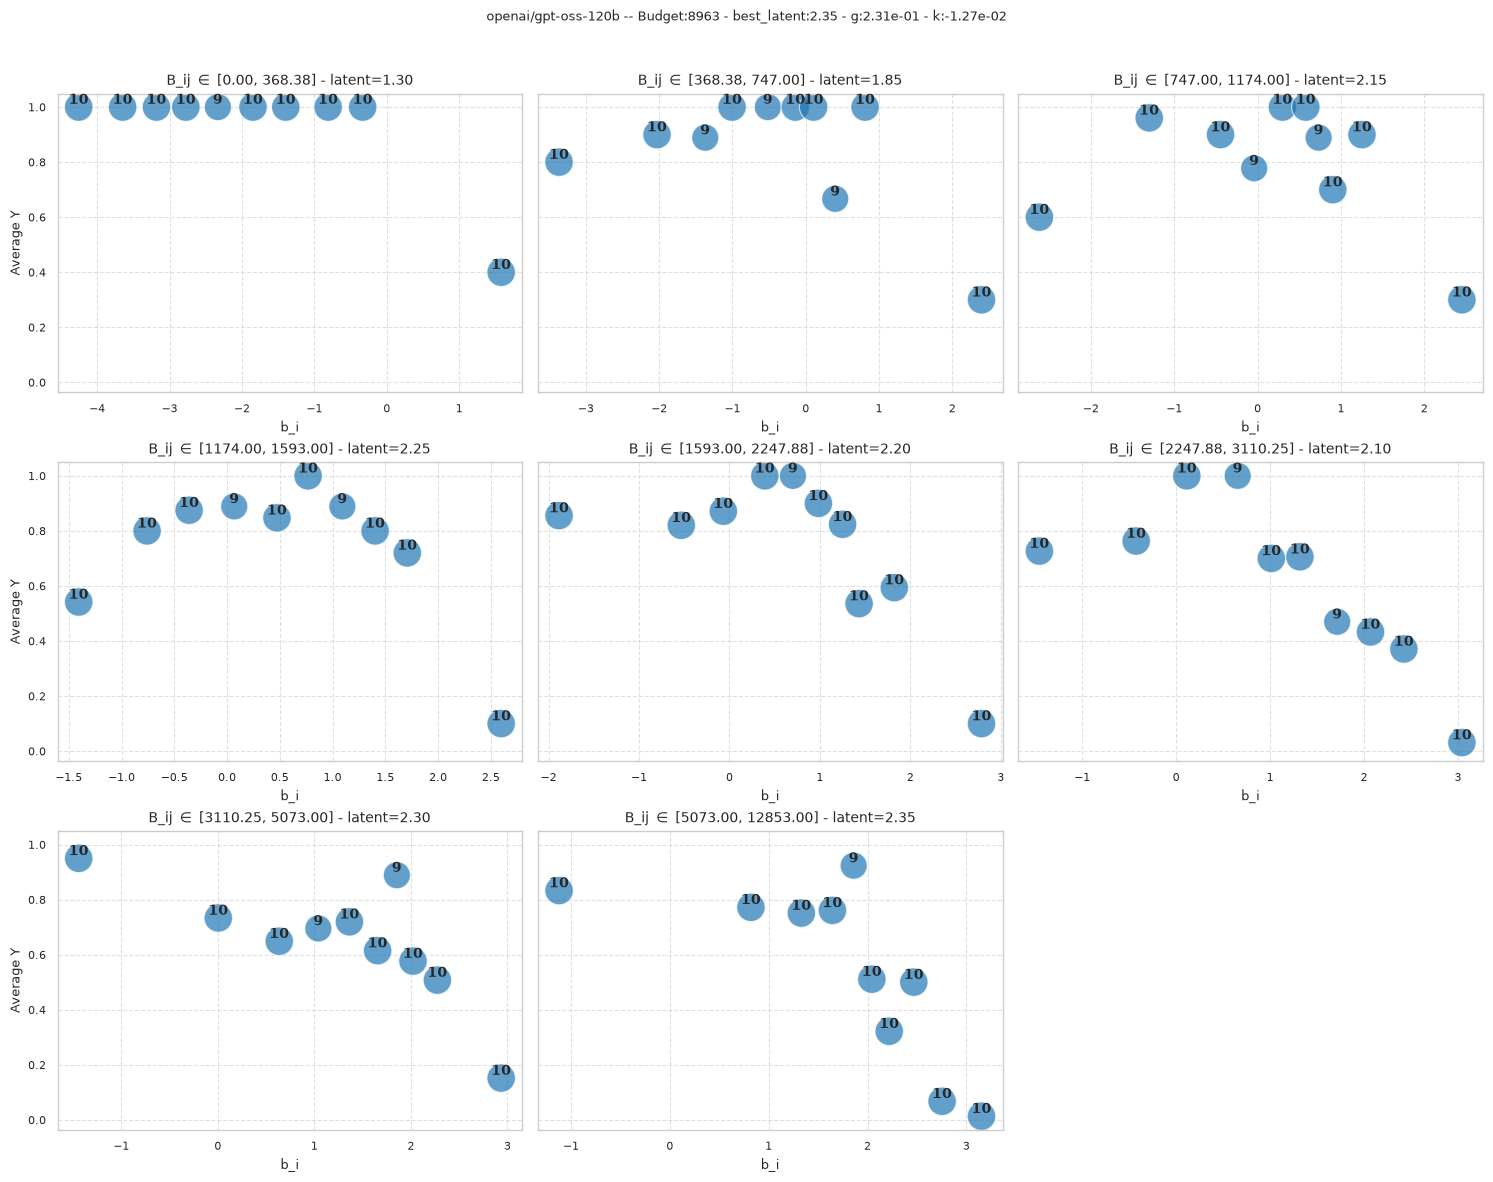

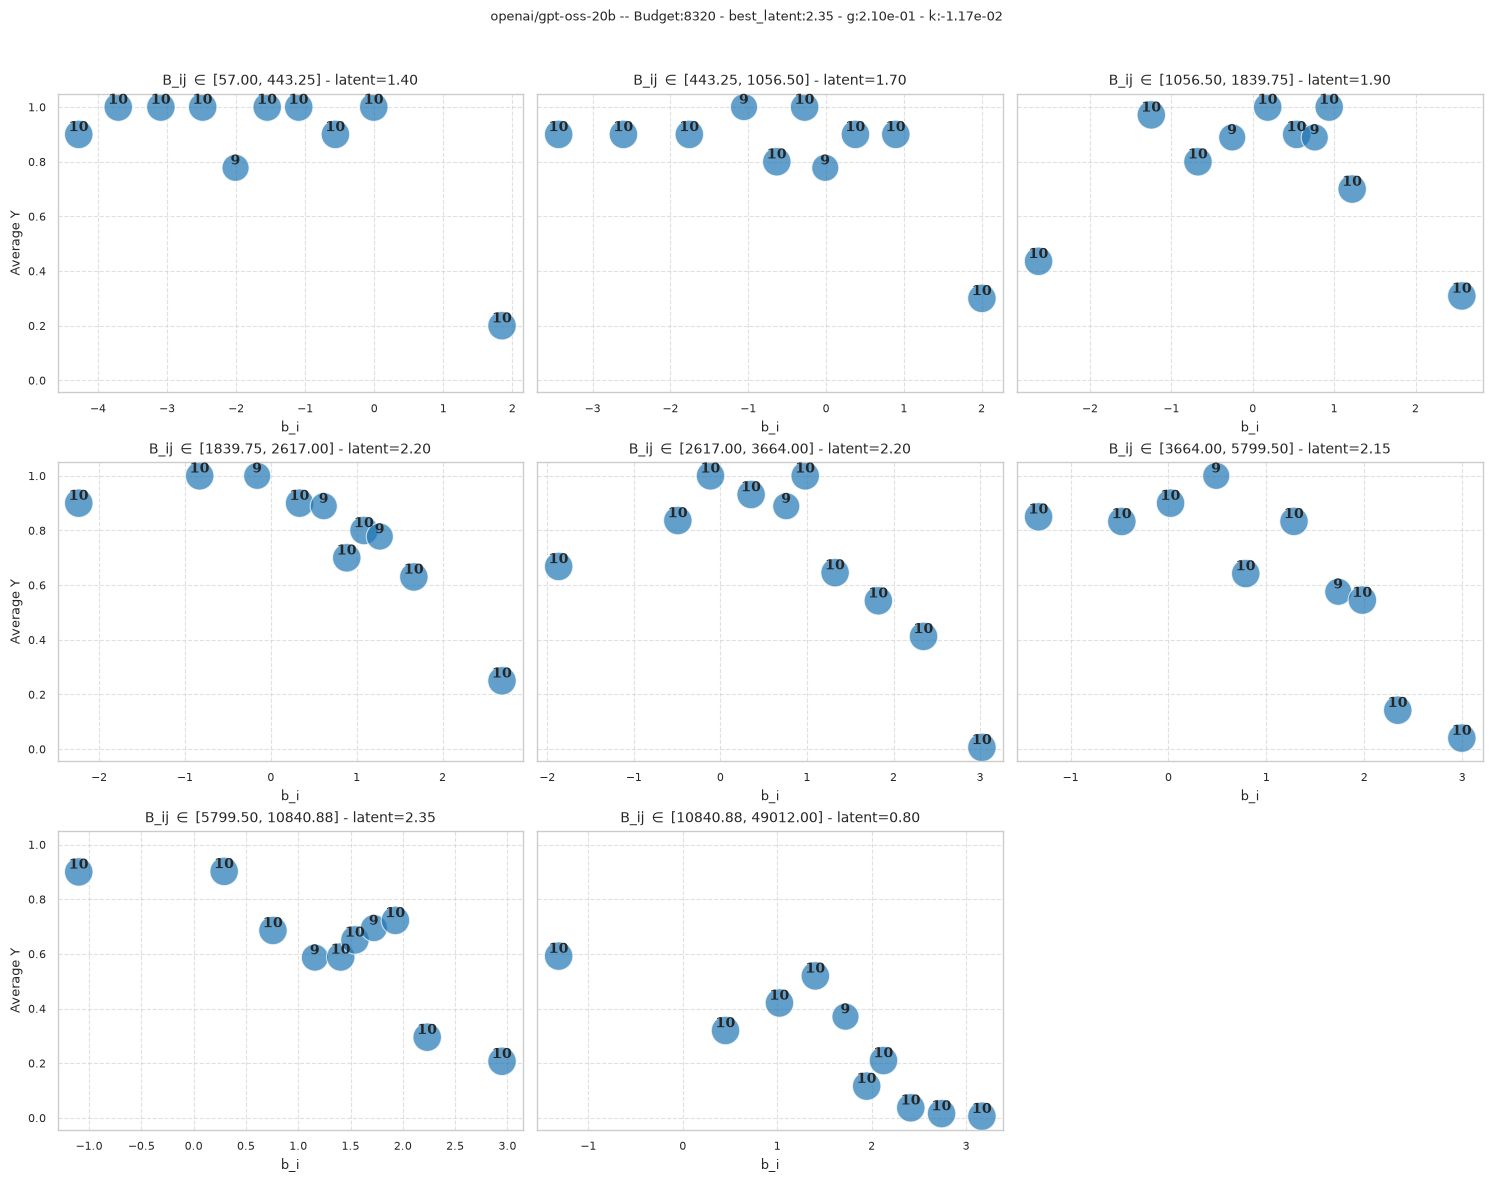

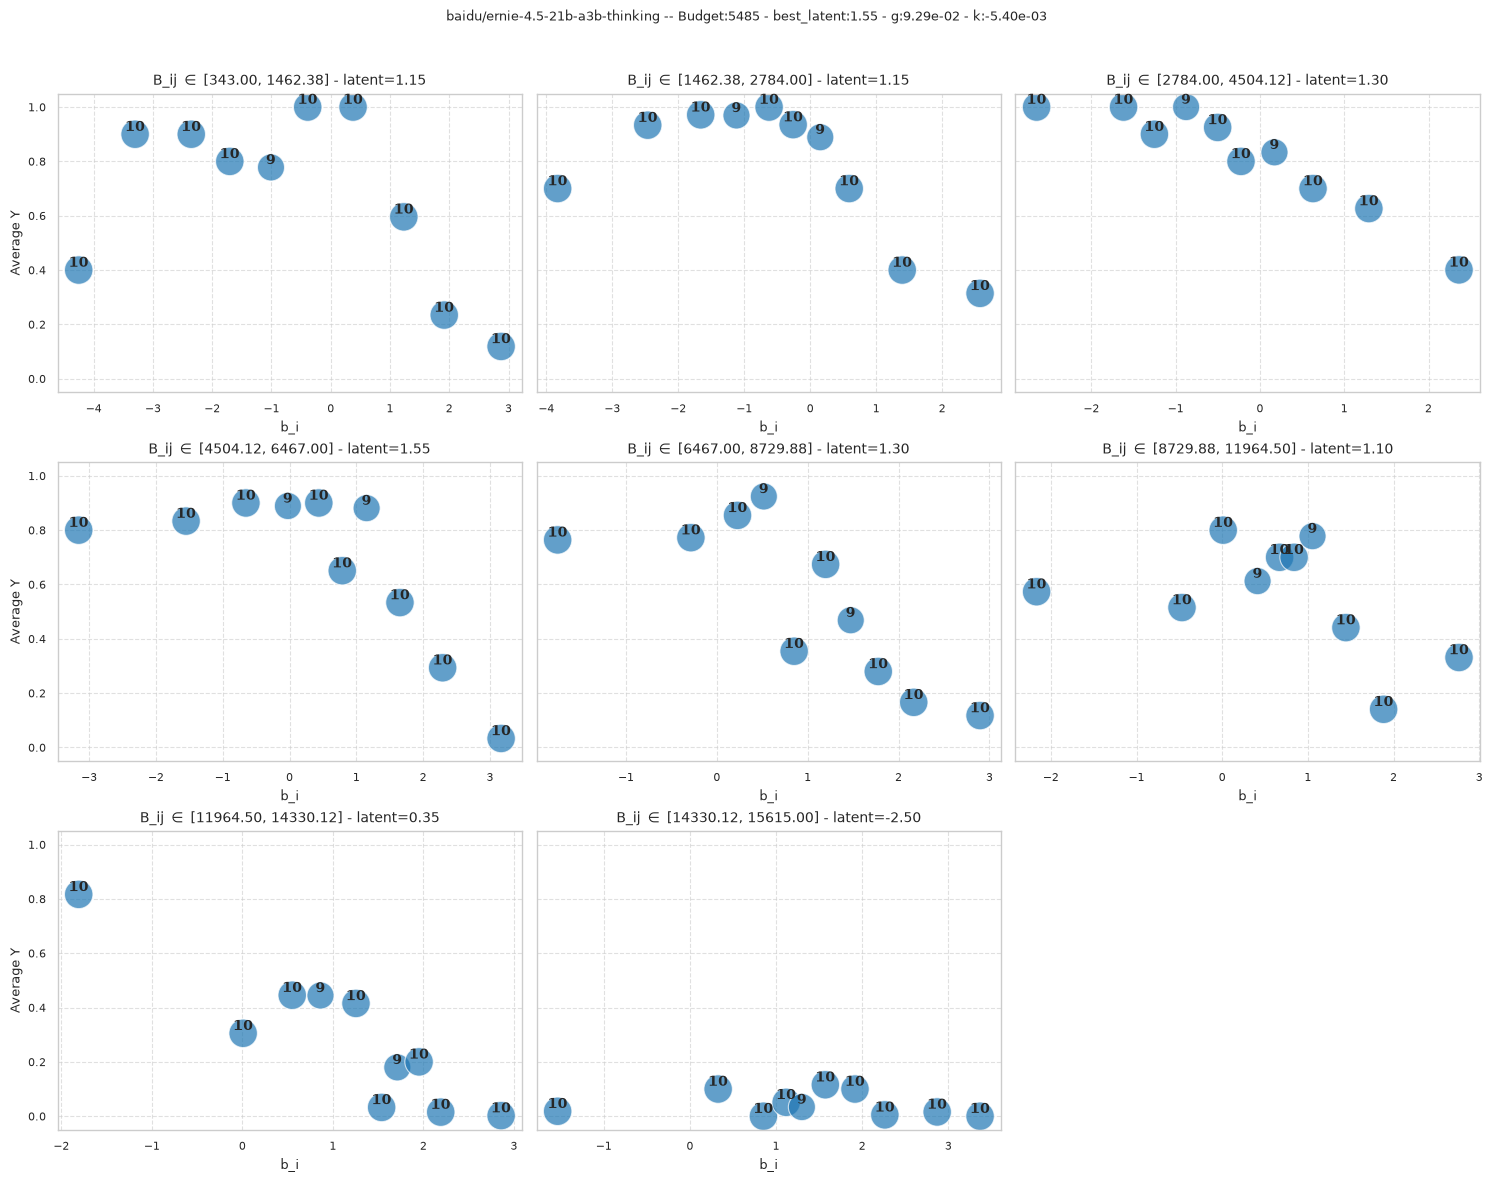

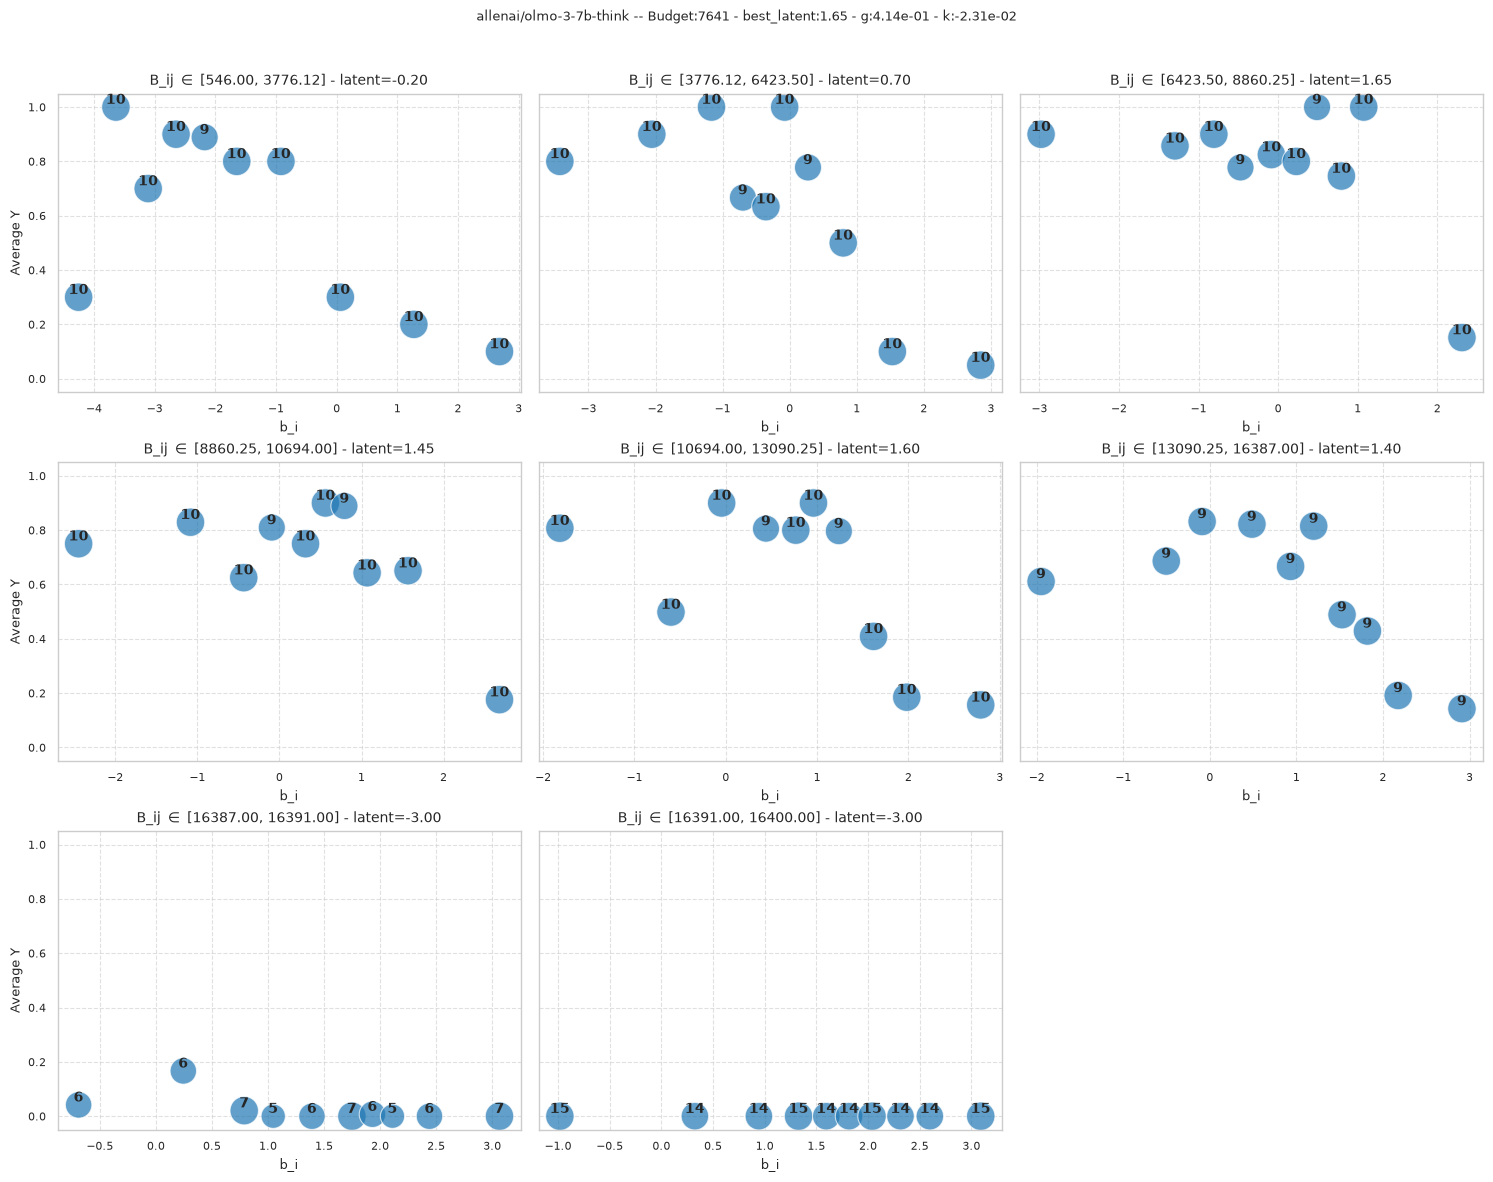

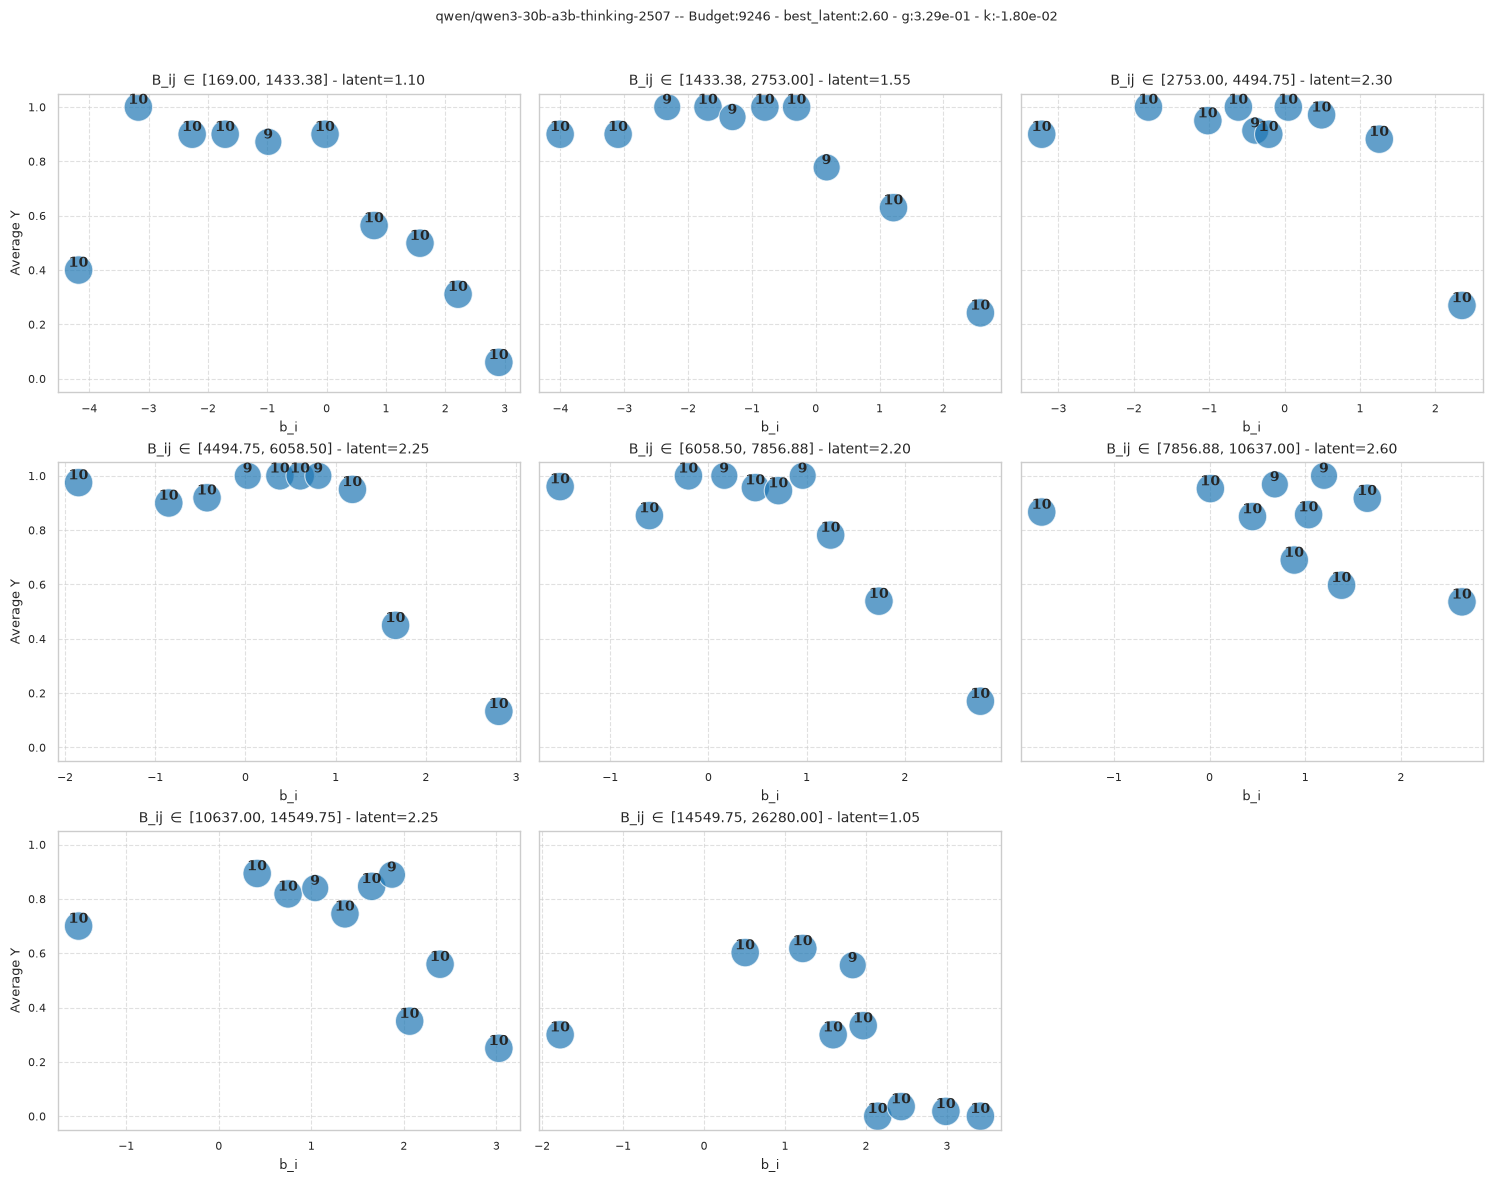

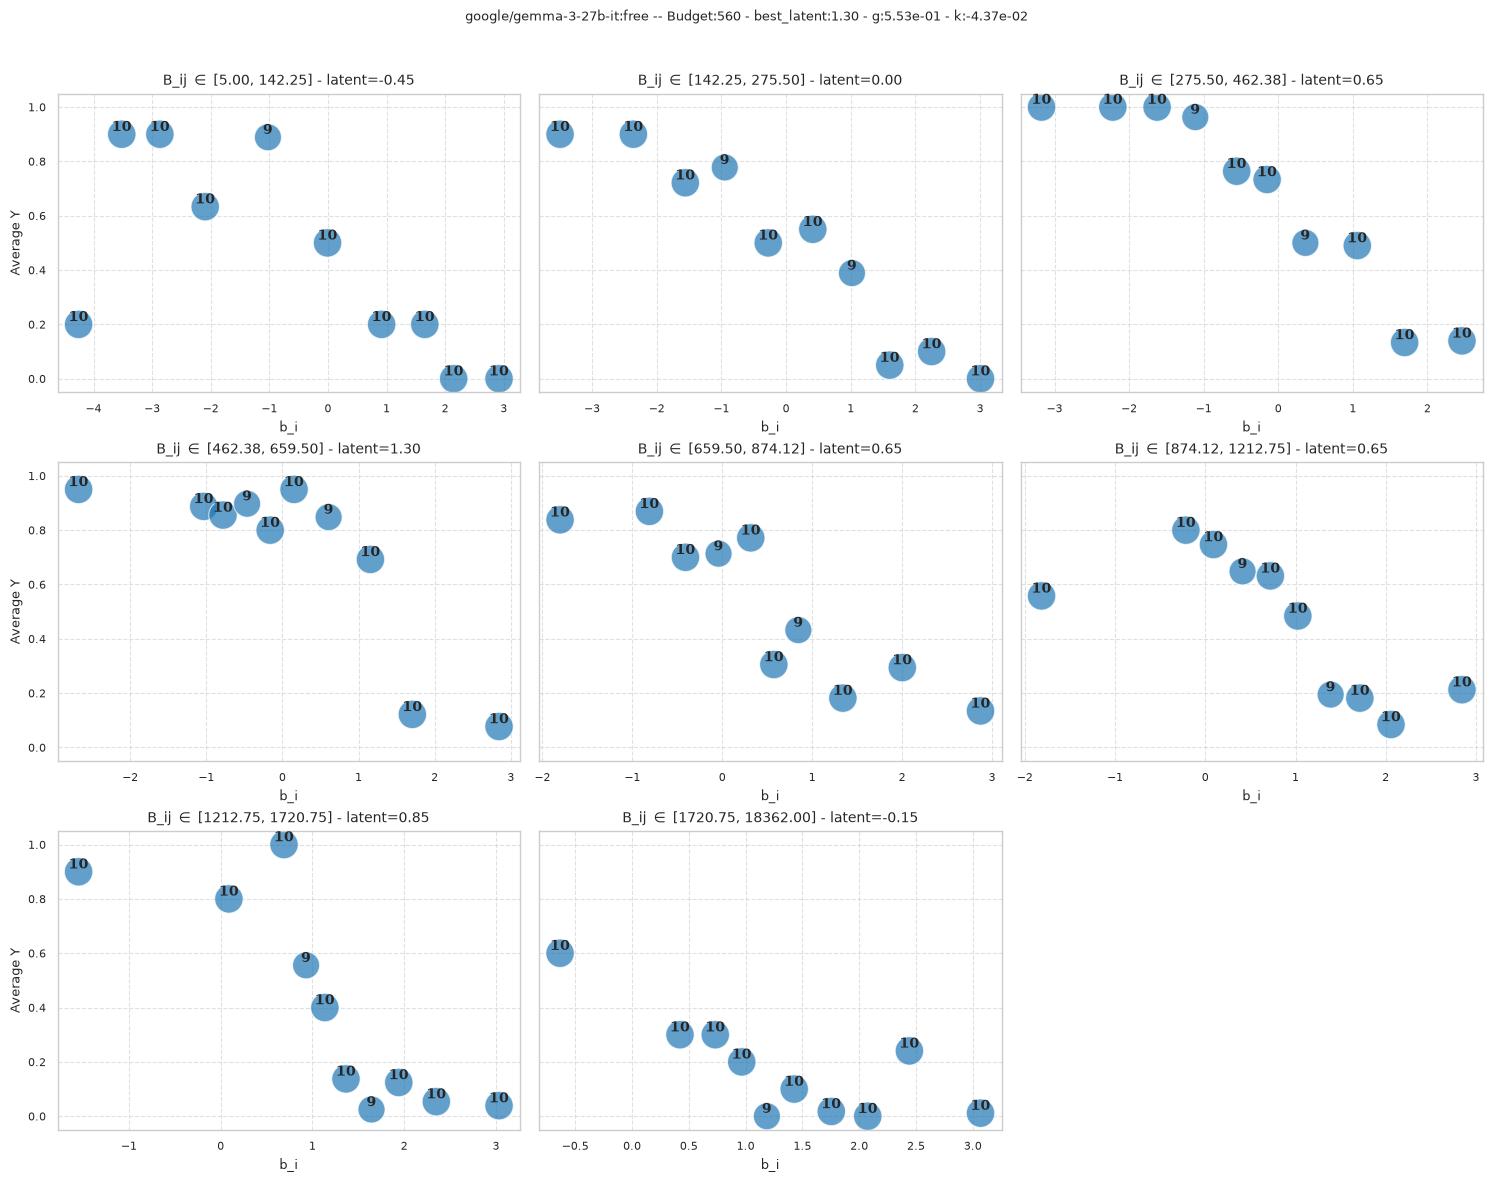

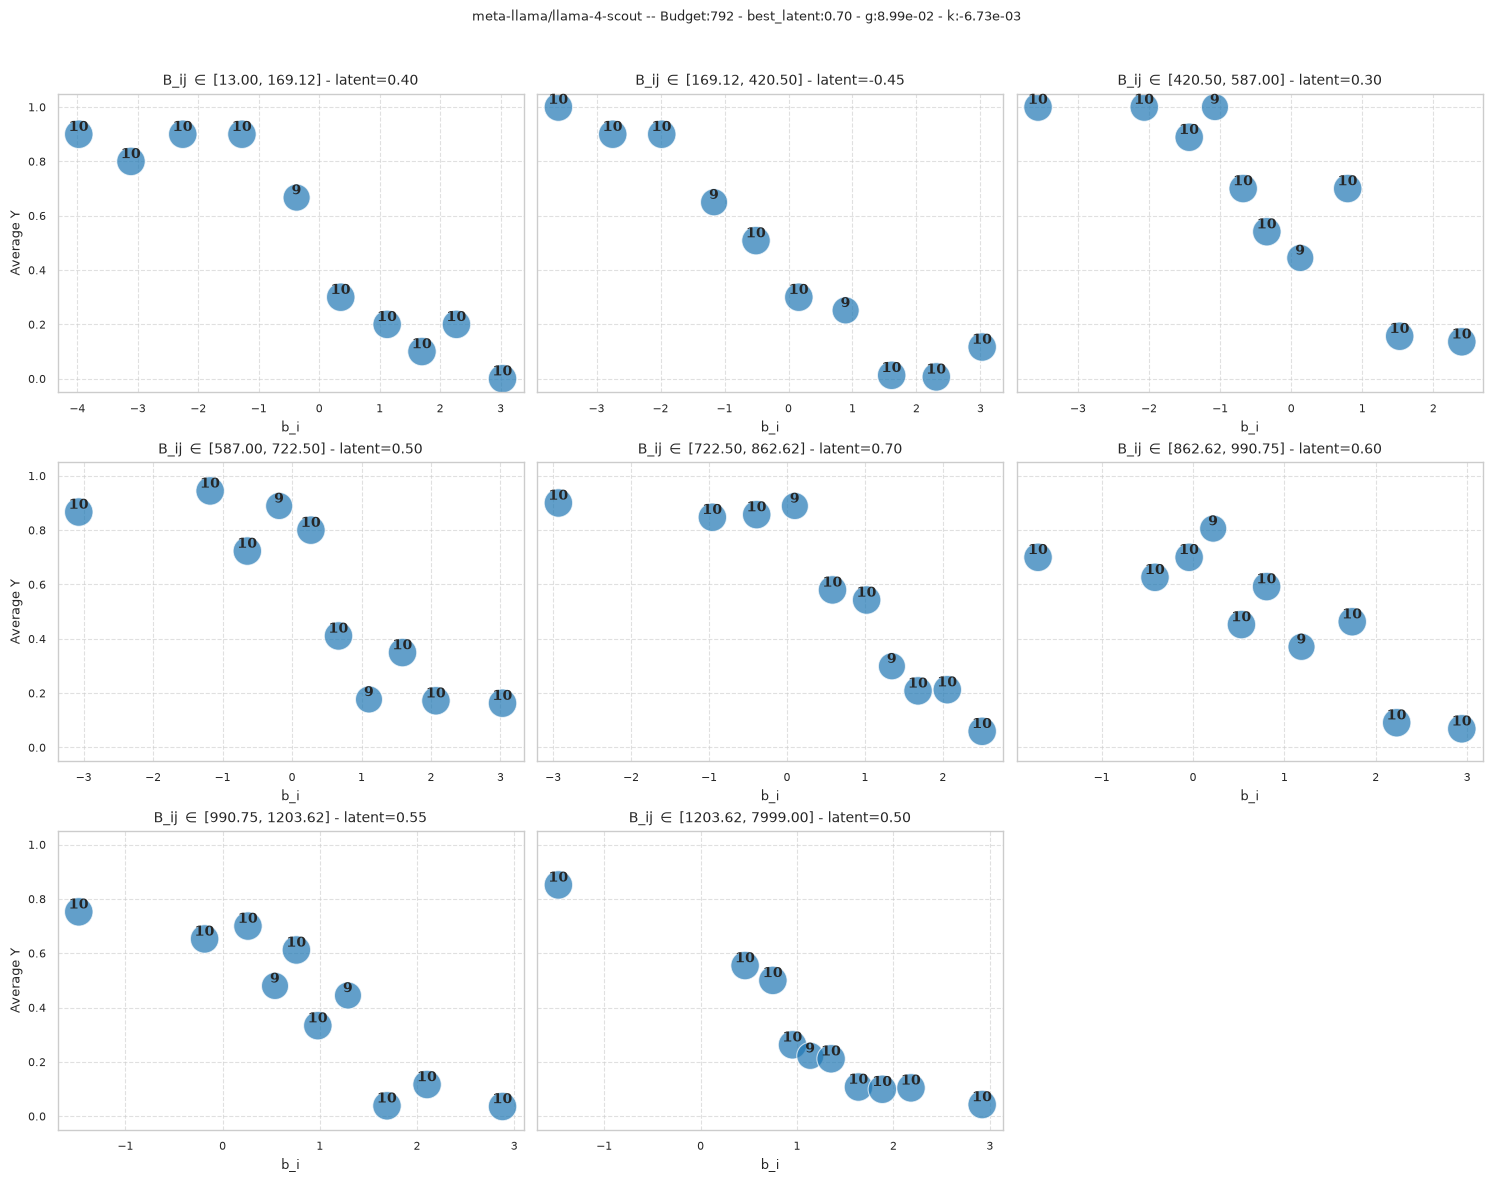

CPU times: user 21.1 s, sys: 833 ms, total: 22 s
Wall time: 22.6 s


In [15]:
%%time
best_B_j_list = []
best_latent_list = []
gamma_list = []
kappa_list = []

show_fig=False
for j in range(len(model_list)):
    ds2 = {
        'x': np.vstack([fit_results.b_i, B_ij[:,j]]).T,
        'y': Y_ij[:, j],
        'title': f'{model_list[j]}',
        'plot_function_argv' : {
            'min_points_per_bin':3, 
            'use_quantiles':True,
            'x1_label':"b_i",
            'x2_label':"B_ij",
            'y_label':"Average Y",
            'fit_object':fit_results, # valid only if slice_axis is B_ij
            }
        }
    
    if j >= 34 and j < 37: show_fig = True # show only some figures to save space and memory

    ret_dict = plot_sliced_bins(ds2['x'], ds2['y'], slice_axis=1, num_slices=8, num_bins_per_slice=10, title=ds2['title'],
                     **ds2['plot_function_argv'], show_fig=show_fig)
    best_B_j_list.append(ret_dict['best_B_j'])
    best_latent_list.append(ret_dict['best_latent'])
    gamma_list.append(ret_dict['gamma'])
    kappa_list.append(ret_dict['kappa'])

In [16]:
posthoc_2nd_pass_dict = {}
posthoc_2nd_pass_dict['best_B_j_list'] = best_B_j_list
posthoc_2nd_pass_dict['best_latent_list'] = best_latent_list
posthoc_2nd_pass_dict['gamma_list'] = gamma_list
posthoc_2nd_pass_dict['kappa_list'] = kappa_list

In [ ]:
joblib.dump(fit_results, 'data/fit_results_2nd_pass.pkl')
joblib.dump(posthoc_2nd_pass_dict, 'data/posthoc_2nd_pass_dict.pkl')

### 3rd-pass

In [17]:
posthoc_2nd_pass_dict = joblib.load('data/posthoc_2nd_pass_dict.pkl')

x0_j = np.log1p(posthoc_2nd_pass_dict['best_B_j_list'])

init_param_dict = {}
init_param_dict['a_i'] = fit_results.a_i
init_param_dict['b_i'] = fit_results.b_i
init_param_dict['gamma_j'] = np.array(posthoc_2nd_pass_dict['gamma_list'])
init_param_dict['kappa_j'] = np.array(posthoc_2nd_pass_dict['kappa_list'])

In [18]:
%%time
data = CalibrationData(Y_ij=Y_ij, B_ij=B_ij, c_i=c_i)

cfg = CalibrationConfig(
gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
ridge_kappa=RIDGE_KAPPA, ridge_gamma=RIDGE_GAMMA, 
ridge_a=RIDGE_A, mu_gamma=MU_GAMMA, ridge_b=RIDGE_B,
mu_kappa=MU_KAPPA, kappa_max=KAPPA_MAX, tol=0.001,
ridge_x0=RIDGE_X0, x0_j=x0_j, optimal_kappa=OPTIMAL_KAPPA_INIT)

calibrator = ReasoningAware3PLCalibrator(cfg)
print(cfg)

fit_results = calibrator.fit(data, strict_Y_int=strict_Y_int, init_param_dict=init_param_dict)

CalibrationConfig(gh_nodes=200, max_iter=200, tol=0.001, seed=0, verbose=True, use_quadratic=True, use_pin_posthoc=False, optimal_kappa=True, tau=0.75, ridge_a=0.5, ridge_b=0.1, ridge_gamma=0.1, ridge_kappa=0.1, mu_a=1.0, mu_b=0.0, mu_gamma=0.1, mu_kappa=-0.01, a_min=0.05, a_max=5.0, gamma_min=0.0, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-05, x0_j=array([5.18738581, 6.80128303, 6.20253552, 6.10255859, 5.43807931,
       6.60529792, 6.05678401, 3.13549422, 5.60580207, 5.53733427,
       4.31748811, 5.24702407, 5.420535  , 5.97888576, 3.66356165,
       4.78749174, 5.05624581, 6.74405919, 4.96284463, 6.52795792,
       3.8501476 , 6.3044488 , 3.8286414 , 5.54126355, 3.4657359 ,
       5.60211882, 7.75362355, 4.44265126, 5.83188248, 6.19440539,
       4.47733681, 3.98898405, 3.80666249, 4.59511985, 7.97418867,
       9.10097183, 9.02653772, 8.60995467, 8.94141463, 9.13205445,
       6.32972091, 6.67582322]), ridge_x0=1000)
iter   1  ll=-13809.304460   dLL=nan
iter   2  ll=-13788.80396

In [19]:
fit_results.info['c_i'] = c_i
fit_results.info['B_ij'] = B_ij

In [ ]:
joblib.dump(fit_results, 'data/fit_results_3rd_pass.pkl')

# Explore Output
Since 3rd-pass has only small improvement over 2nd-pass, we then stop here.

The following Table almost exactly reproduce Table-4 in the paper, where **BaseTheta** denote $\theta_j^{\text{base}}$, **BestTheta** denote $\theta_j^{\text{opt}}$ and **EffTheta** denote $\theta_{ij}^{\text{eff}}$ evaluated at $\bar{X}_{:,j}$ (this quantity indicated average effective theta in the real experiments which is lower than the theoretical $\theta_j^{\text{opt}}$)

In [19]:
fit_results = joblib.load('data/fit_results_3rd_pass.pkl')

In [20]:
from reasoning_aware_irt.gem_quad import compute_louis_se

# calculate Louis standard error as explained in Appendix A
out = compute_louis_se(result=fit_results, data=data)

In [21]:
from reasoning_aware_irt.posthoc import print_model_summary
summary_data = print_model_summary(model_list, fit_results, Y_ij, se_dict=out, sort_by="best_theta")

openai/gpt-oss-120b                 | BaseTheta:   0.54 ± 0.072| Gamma:  0.3754 ± 0.1212| Kappa: -0.0205 ± 0.0146 |Avg Y :   0.737
Best Budget:  9540|BestTheta:   2.255 ±   1.659|Avg. EffTheta:   2.215 ±   0.639|

qwen/qwen3-30b-a3b-thinking-2507    | BaseTheta:   0.33 ± 0.049| Gamma:  0.3569 ± 0.1268| Kappa: -0.0197 ± 0.0138 |Avg Y :   0.722
Best Budget:  8665|BestTheta:   1.949 ±   1.616|Avg. EffTheta:   1.948 ±   0.643|

openai/gpt-oss-20b                  | BaseTheta:   0.99 ± 0.052| Gamma:  0.2189 ± 0.0921| Kappa: -0.0127 ± 0.0107 |Avg Y :   0.686
Best Budget:  5591|BestTheta:   1.939 ±   1.126|Avg. EffTheta:   1.938 ±   0.447|

xiaomi/mimo-v2-flash:free           | BaseTheta:  -0.57 ± 0.066| Gamma:  0.5991 ± 0.0790| Kappa: -0.0368 ± 0.0090 |Avg Y :   0.684
Best Budget:  3412|BestTheta:   1.864 ±   0.878|Avg. EffTheta:   1.863 ±   0.360|

baidu/ernie-4.5-21b-a3b-thinking    | BaseTheta:   0.33 ± 0.036| Gamma:  0.1409 ± 0.1105| Kappa: -0.0096 ± 0.0122 |Avg Y :   0.544
Best Budget: 

/workspaces/reasoning-aware-irt/reasoning_aware_irt/posthoc.py:222: SyntaxWarning: invalid escape sequence '\i'
  title = f"{slice_label} $\in$ [{slice_edges[target_slice_idx]:.2f}, {slice_edges[target_slice_idx+1]:.2f}]"


## Helper Functions to plot the Unified Benchmark-Ability diagram (Fig. 2)

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from typing import List, Dict, Union, Optional, Tuple
from matplotlib.lines import Line2D

def plot_ability_vs_difficulty(
    student_data: List[Dict[str, Union[str, float, int, None]]], 
    problem_sets: Dict[str, np.ndarray], 
    overall_student_abilities: Optional[np.ndarray] = None,  # <-- NEW ARGUMENT
    plot_mode: str = 'boxplot',  # Options: 'boxplot', 'violin'
    violin_percentiles: Tuple[float, float] = (10.0, 90.0),
    save_path: Optional[str] = None, text_fontsize=10,
    legend_loc='lower left', legend_fontsize='medium',
    figsize=(12, 4),
    show_trajectory_legend=True,
) -> None:
    """
    Visualizes individual student learning trajectories against the marginal 
    distributions of multiple problem set difficulties p(b).
    """
    # 1. Pre-compute Global Boundaries
    all_student_vals = [val for s in student_data for val in (s["base"], s["effective"], s["optimal"])]
    
    # Include the new overall distribution in the global boundaries
    if overall_student_abilities is not None:
        if plot_mode == 'violin':
            p_lower, p_upper = np.percentile(overall_student_abilities, violin_percentiles)
            all_student_vals.extend(overall_student_abilities[(overall_student_abilities >= p_lower) & (overall_student_abilities <= p_upper)])
        else:
            all_student_vals.extend(overall_student_abilities)
    
    if plot_mode == 'violin':
        all_prob_vals = []
        for p in problem_sets.values():
            p_lower, p_upper = np.percentile(p, violin_percentiles)
            all_prob_vals.extend(p[(p >= p_lower) & (p <= p_upper)])
    else:
        all_prob_vals = [val for p_set in problem_sets.values() for val in p_set]

    min_all = min(min(all_student_vals), min(all_prob_vals)) - 0.5
    max_all = max(max(all_student_vals), max(all_prob_vals)) + 0.5

    # 2. Setup Axes
    fig, ax = plt.subplots(figsize=figsize)

    num_students = len(student_data)
    num_problem_sets = len(problem_sets)
    x_positions_students = range(1, num_students + 1)
    x_positions_problems = [num_students + 1.5 + i for i in range(num_problem_sets)]
    
    # 2.5 Plot Overall Student Abilities (The New Left-Side Plot at x=0)
    if overall_student_abilities is not None:
        if plot_mode == 'boxplot':
            ax.boxplot(
                [overall_student_abilities], positions=[0], widths=0.6, 
                patch_artist=True, boxprops=dict(facecolor='#9467bd', alpha=0.5), # Purple
                medianprops=dict(color='black', lw=1.5)
            )
        elif plot_mode == 'violin':
            p_lower, p_upper = np.percentile(overall_student_abilities, violin_percentiles)
            bounded_overall = overall_student_abilities[(overall_student_abilities >= p_lower) & (overall_student_abilities <= p_upper)]
            
            v_overall = ax.violinplot(
                [bounded_overall], positions=[0], widths=0.8, showmeans=True
            )
            for pc in v_overall['bodies']:
                pc.set_facecolor('#9467bd') # Purple to contrast with green problem sets
                pc.set_edgecolor('black')
                pc.set_alpha(0.5)

    # 3. Plot Students
    for i, s in zip(x_positions_students, student_data):
        # Arrow for \Delta \theta
        ax.annotate(
            # '', xy=(i, s["effective"]), xytext=(i, s["base"]),
            '', xy=(i, s["optimal"]), xytext=(i, s["base"]),
            arrowprops=dict(arrowstyle="->", lw=1.5, color='#1f77b4', mutation_scale=10)
        )
        # Asterisk for Optimal
        ax.plot(i, s["optimal"], marker='*', color='#d62728', markersize=9)
        
        # Current resource usage (annotated below the base ability)
        if s.get("current_resources") is not None:
            ax.text(
                i, s["base"] - 0.15, f'{s["current_resources"]:.2f}', 
                ha='center', va='top', fontsize=text_fontsize,
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1)
            )
            
        # Optimal resource usage (annotated above the optimal ability)
        if s.get("optimal_resources") is not None:
            ax.text(
                i, s["optimal"]+s["eff_se"] + 0.15, f'{s["optimal_resources"]}', 
                ha='center', va='bottom', fontsize=text_fontsize,
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1)
            )

        if s.get("classic") is not None:
            ax.plot(i, s["classic"], marker='o', color='#8c564b', markersize=10, 
                    markerfacecolor='none', markeredgewidth=2)
        
        # --- Dashed-Red-Bracket for SE ---
        if s.get("eff_se") is not None:
            eb = ax.errorbar(i, 
                             s["optimal"], 
                             yerr=s["eff_se"], 
                             fmt='none', ecolor='#d62728', capsize=5, capthick=1.5)
            eb[-1][0].set_linestyle('--')

    # 4. Plot Problem Sets
    if num_problem_sets > 0:
        dataset_list = list(problem_sets.values())
        
        if plot_mode == 'boxplot':
            ax.boxplot(
                dataset_list, positions=x_positions_problems, widths=0.6, 
                patch_artist=True, boxprops=dict(facecolor='#2ca02c', alpha=0.5), # Green
                medianprops=dict(color='black', lw=1.5)
            )
            
        elif plot_mode == 'violin':
            bounded_data = []
            for p in dataset_list:
                p_lower, p_upper = np.percentile(p, violin_percentiles)
                bounded_data.append(p[(p >= p_lower) & (p <= p_upper)])
            
            violins = ax.violinplot(
                bounded_data, positions=x_positions_problems, widths=1.0, showmeans=True
            )
            for pc in violins['bodies']:
                pc.set_facecolor('#2ca02c')
                pc.set_edgecolor('black')
                pc.set_alpha(0.5)

    # 5. Global Formatting
    ax.set_ylim(min_all, max_all)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    ax.set_ylabel(r"Unified Latent Scale ($\theta, b$)", fontsize=8)
    ax.set_title(r"Model-Ability Trajectories and Item Difficulties", fontsize=8, fontweight='bold')

    # Dynamically build labels to include the new left-side plot if it exists
    all_x_positions = list(x_positions_students) + x_positions_problems
    all_labels = [s["name"] for s in student_data] + list(problem_sets.keys())
    
    if overall_student_abilities is not None:
        all_x_positions = [0] + all_x_positions
        all_labels = ["Overall Ability"] + all_labels
    
    ax.set_xticks(all_x_positions)
    ax.set_xticklabels(all_labels, rotation=20, ha='right')

    # 6. Legend
    if show_trajectory_legend:
        custom_lines = [Line2D([0], [0], color='#1f77b4', lw=2, marker='>', markersize=8)]
        # custom_names = [r'Effective Trajectory ($\theta^{base} \to \theta^{opt}$)']
        custom_names = [r'Trajectory: $\theta^{\mathrm{base}} \to \theta^{\mathrm{opt}}$']
    else:
        custom_lines = []
        custom_names = []
    custom_lines += [ Line2D([0], [0], color='w', marker='*', markerfacecolor='#d62728', markersize=10),
                      Line2D([0], [0], color='w', marker='o', markeredgecolor='#8c564b', 
                            markerfacecolor='none', markersize=8, markeredgewidth=2)
                    ]
    custom_names += [r'$\theta^{\mathrm{opt}}_j \pm$ SE', r'$\theta^{\mathrm{classic}}_j$']
    # custom_names += [r'($\theta^{opt} \pm SE$)', r'($\theta^{classic}$)']
    ax.legend(
        custom_lines, 
        custom_names,
        loc=legend_loc, 
        framealpha=0.9,
        bbox_to_anchor=(0.25, 0.0),
        fontsize=legend_fontsize
    )
    # plt.legend(loc='lower center', bbox_to_anchor=(0.25, 0.0))
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight', dpi=300, pad_inches=0.0, transparent=True)
        print(f"Plot saved to {save_path} using {plot_mode} mode.")
    else:
        plt.show()

In [23]:
student_data = []
for j, d in enumerate(summary_data):
        
    # Prepare format for plot_ability_vs_difficulty
    student_data.append({
        "m": d['m'], # for latex printing
        "name": d['m'].split('/')[-1].split(':')[0],
        "base": d['b_theta'],
        "effective": d['eff_theta'],
        "optimal": d['best_theta'],
        "eff_se": d['eff_se'],
        "optimal_se": d['best_se'],
        # "classic": d['classic_theta'], <-- scaled-normalized classic results can be put here
        "current_resources": d['avg_y'],
        "optimal_resources": int(d['optimal_budget']),
    })
    

In [24]:
best_theta_np = np.array([student_data[j]['optimal'] for j in range(len(student_data))])

In [25]:
ID1=0
ID2=len(B_language)
ID3=len(B_language)+len(B_coding)
ID4=len(B_language)+len(B_coding)+len(B_reasoning)

b_i_by_category_dict = {
        "language": fit_results.b_i[ID1:ID2],
        "coding": fit_results.b_i[ID2:ID3],
        "reasoning": fit_results.b_i[ID3:ID4],
        "math": fit_results.b_i[ID4:],
    }


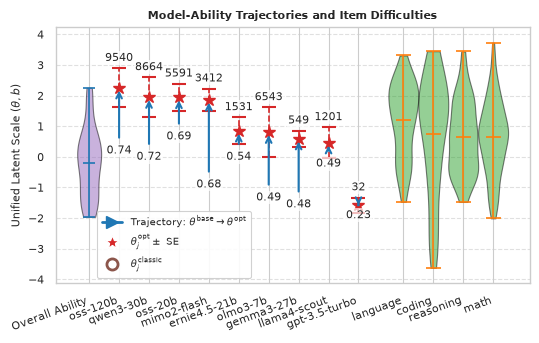

In [26]:
student_plot_data2 = np.array(student_data)
student_plot_data2[0]['name'] = 'oss-120b'
student_plot_data2[1]['name'] = 'qwen3-30b'
student_plot_data2[2]['name'] = 'oss-20b'
student_plot_data2[3]['name'] = 'mimo2-flash'
student_plot_data2[4]['name'] = 'ernie4.5-21b'
student_plot_data2[5]['name'] = 'olmo3-7b'
student_plot_data2[7]['name'] = 'gemma3-27b'
# student_plot_data2[8]['name'] = 'gemini-1.5-pro'
student_plot_data2[9]['name'] = 'llama4-scout'
student_plot_data2[33]['name'] = 'gpt-3.5-turbo'

plot_ability_vs_difficulty(
        student_data=student_plot_data2[np.r_[:6, 7, 9, 33]], 
        problem_sets=b_i_by_category_dict,
        overall_student_abilities = best_theta_np,
        plot_mode='violin',
        violin_percentiles=(10.0, 100.0),
        save_path=None, #"Fig2.pdf",
        figsize=(5.5,3.5),
        show_trajectory_legend=True,
        text_fontsize=8,
        legend_fontsize='small',
        legend_loc='lower center' # center left, upper center, lower left
    )


NOTE that Classic 3PL can be reproduced by following notebooks regarding fig1 (how to estimate with Classic 3PL), and follow the same pipeline in this notebook (and finally normalize classic's results to the same scale as our reasoning-aware results)